# Bayesian Active Learning of a Protein Formulation Phase Map

This case study runs a single active learning campaign on the AFL-agent virtual protein / glycerol / temperature instrument, `ProteinGlycerolTemperaturePhaseMap`. The instrument reproduces the phase boundaries of the AFL-bioformulations study: a protein solution that is single phase (Single), shows a solid-liquid separation (S-L) or a liquid-liquid separation (L-L) depending on the protein and glycerol content and the temperature.

The campaign is the *baseline* strategy: every decision is made on a grid.

1. **Classifier.** A `DirichletGPExtrapolator` is fit to the measured phase labels on the three-dimensional design space (protein, temperature, glycerol).
2. **Composition.** The predictive entropy of the classifier is marginalised over temperature with `MarginalEntropyOverDimension` and `MaxValueAF` picks the most uncertain (protein, glycerol) composition that has not been measured yet.
3. **Temperatures.** At that composition, `MarginalEntropyAlongDimension` evaluates the entropy along the temperature axis and `MaxValueAF` selects a batch of the most uncertain temperatures that have not been measured there.

`PhaseMapF1Score` scores the classifier against the simulator on a phase-stratified test set after every fit, so the quality of the learned phase map can be tracked over the campaign. 

The companion notebook, *Manifold Active Learning of a Protein Formulation Phase Map*, replaces the two grid searches with a gradient-based search over compositions and temperature profiles.

## Set Up the Environment

Import the libraries used in the campaign and define every setting in one place. The design-space limits are those of the virtual instrument, `standardize=True` keeps the feature scaling inside the classifier so all values below are in instrument units.

In [1]:
# Uncomment this cell if you need to install AFL-agent (torch, gpytorch and pyro-ppl are pulled in).
# !pip install "AFL-agent @ git+https://github.com/usnistgov/afl-agent"

In [2]:
import netCDF4  # noqa: F401  load xarray's NetCDF/HDF5 build before AFL imports h5py; in some
#                               environments the two HDF5 builds conflict and NetCDF reads fail otherwise
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr

from AFL.double_agent.AcquisitionFunction import MaxValueAF
from AFL.double_agent.benchmarking import PhaseMapF1Score
from AFL.double_agent.Generator import CartesianGrid
from AFL.double_agent.Pipeline import Pipeline
from AFL.double_agent.PyTorchExtrapolator import DirichletGPExtrapolator
from AFL.double_agent.Utility import MarginalEntropyAlongDimension, MarginalEntropyOverDimension
from AFL.double_agent.VirtualInstruments import ProteinGlycerolTemperaturePhaseMap

from helpers import plot_baseline_iteration, plot_phase_map, plot_score_history  # plotting, see helpers.py in this folder

np.set_printoptions(precision=3, suppress=True)

/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [3]:
# campaign
SEED = 1000  # numpy / torch seed and the seed of the benchmark test set
N_SAMPLES = 10  # number of compositions (one batch of temperatures each) to acquire
N_TEMPERATURES = 4  # temperatures measured per composition
INITIAL_COMPOSITION = {"protein": 40.0, "glycerol": 5.0}  # the one composition measured before the campaign
INITIAL_TEMPERATURES = [5.0, 10.0, 20.0, 30.0, 40.0, 45.0]  # ... and the temperatures it is measured at
PLOT_EVERY_ITERATION = False  # draw the six-panel figure after every iteration (slower, more output)

# design space
LIMITS = {"protein": (0.5, 75.0), "glycerol": (0.5, 10.0), "temperature": (0.5, 45.0)}
GRID_STEPS = 20  # 3D grid on which the GP posterior (phase map) is evaluated

# phase classifier
GP_PARAMS = {"kernel": "matern", "method": "mll", "n_iterations": 200, "verbose": False}
MODEL_DIR = tempfile.mkdtemp(prefix="afl_baseline_gp_")  # where the fitted GP is written each iteration

# acquisition
DECISION_RTOL = 0.05  # MaxValueAF picks randomly among grid points within this fraction of the maximum
EXCLUSION_RADIUS = 0.1  # width (instrument units) of the exclusion zone around measured points

# benchmark
N_TEST_PER_PHASE = 100  # stratified test points per phase of the F1 score
F1_AVERAGE = "weighted"  # sklearn f1_score averaging: weighted, macro, micro or None (per phase)

## The Virtual Instrument

`ProteinGlycerolTemperaturePhaseMap.measure` exposes one (protein, glycerol) composition at several temperatures and returns one sample per temperature with the simulated scattering, the `design_space` coordinates in the instrument's feature order and the integer phase label in `phases`. The feature order of the instrument is what the pipeline below works in.

In [4]:
sim = ProteinGlycerolTemperaturePhaseMap()
COMPONENTS = sim.components  # feature order of the instrument: protein, temperature, glycerol
XY = [c for c in COMPONENTS if c != "temperature"]  # composition components: protein, glycerol
XY_PREFIX = "_".join(XY)  # MarginalEntropyOverDimension names its outputs "<complement dims>_*"
COMPONENTS

['protein', 'temperature', 'glycerol']

Since the instrument is virtual, its ground truth is available. `virtual_instrument_labels` evaluates it on the same grid the classifier will be evaluated on; the campaign has to recover this map from as few measurements as possible.

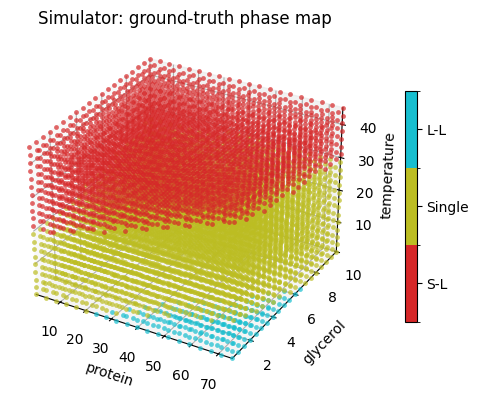

In [5]:
from AFL.double_agent.benchmarking import virtual_instrument_labels

grid_axes = [np.linspace(*LIMITS[c], GRID_STEPS) for c in COMPONENTS]
grid = np.stack(np.meshgrid(*grid_axes, indexing="ij"), axis=-1).reshape(-1, len(COMPONENTS))
true_labels = virtual_instrument_labels(sim, grid)

plot_phase_map(grid, true_labels, LIMITS, COMPONENTS)
plt.show()

## Build the Pipeline

The pipeline is fixed for the whole campaign; only the dataset it is applied to grows. 

- `CartesianGrid` builds the evaluation grid, the `DirichletGPExtrapolator` fits the classifier and writes its predictions (`phase_mean`, `phase_y_prob`, `phase_entropy`) on the grid and a reference to the fitted model to `phase_model`, which `PhaseMapF1Score` loads to score it against the simulator.
- The acquisition is two grid searches:
    - `MarginalEntropyOverDimension` averages the phase probabilities over the temperature axis of the grid and takes the entropy, which gives one utility per (protein, glycerol) composition; it also writes the composition grid (`protein_glycerol_domain`) and the compositions that have already been measured (`protein_glycerol_sampled`). 
    - `MaxValueAF` picks the maximum, excluding the measured compositions. 
    - `MarginalEntropyAlongDimension` then evaluates the entropy along the temperature axis at that composition and a second `MaxValueAF` selects `N_TEMPERATURES` temperatures, excluding those already measured there.

In [6]:
with Pipeline(name="baselineAL") as pipeline:
    CartesianGrid(
        output_variable="design_space_grid",
        sample_dim="ds_grid",
        component_dim="ds_dim",
        grid_spec={c: {"min": LIMITS[c][0], "max": LIMITS[c][1], "steps": GRID_STEPS} for c in COMPONENTS},
        name="Grid-DesignSpace",
    )
    # phase classifier on (protein, temperature, glycerol); feature scaling lives inside the model
    DirichletGPExtrapolator(
        feature_input_variable="design_space",
        predictor_input_variable="phases",
        output_prefix="phase",
        grid_variable="design_space_grid",
        grid_dim="ds_grid",
        sample_dim="sample",
        component_dim="ds_dim",
        params=GP_PARAMS,
        standardize=True,
        bounds={c: LIMITS[c] for c in COMPONENTS},
        model_uri=MODEL_DIR,  # writes the model ref to "phase_model" for PhaseMapF1Score
        name="DirichletGPExtrapolator-PhaseLabels",
    )
    # benchmark: F1 score of the classifier against the simulator on a phase-stratified test set
    # (drawn once, equal points per phase); writes "benchmark_f1", "benchmark_accuracy", ...
    PhaseMapF1Score(
        ground_truth=sim,
        bounds={c: LIMITS[c] for c in COMPONENTS},
        model_variable="phase_model",
        average=F1_AVERAGE,
        n_per_phase=N_TEST_PER_PHASE,
        seed=SEED,
        output_prefix="benchmark",
        name="PhaseMapF1Score",
    )
    # stage 1: composition on the (protein, glycerol) grid maximising the entropy of the phase
    # probability marginalised over temperature; measured compositions are excluded
    MarginalEntropyOverDimension(
        input_variable="phase_y_prob",
        coordinate_dims=["temperature"],
        component_dim="ds_dim",
        grid_variable="design_space_grid",
        sample_variable="design_space",
        output_variable="composition_utility",  # also writes "<XY_PREFIX>_domain" and "<XY_PREFIX>_sampled"
        name="MarginalEntropy-OverTemperature",
    )
    MaxValueAF(
        input_variables=["composition_utility"],
        grid_variable=f"{XY_PREFIX}_domain",
        grid_dim=f"{XY_PREFIX}_n",
        output_prefix="composition",
        output_variable="composition_next",
        decision_rtol=DECISION_RTOL,
        excluded_comps_variables=[f"{XY_PREFIX}_sampled"],
        excluded_comps_dim=f"{XY_PREFIX}_d",
        exclusion_radius=EXCLUSION_RADIUS,
        count=1,
        sample_dim="composition_next_n",
        name="MaxValueAF-Composition",
    )
    # stage 2: batch of temperatures on the temperature grid at ``composition_next`` from the top of
    # the classifier entropy along the temperature axis; temperatures already measured there are excluded
    MarginalEntropyAlongDimension(
        input_variable="phase_y_prob",
        conditioning_point="composition_next",
        coordinate_dim="temperature",
        grid_variable="design_space_grid",
        sample_variable="design_space",
        component_dim="ds_dim",
        output_variable="temperature_utility",  # also writes "temperature_domain" and "temperature_sampled"
        name="MarginalEntropy-AlongTemperature",
    )
    MaxValueAF(
        input_variables=["temperature_utility"],
        grid_variable="temperature_domain",
        grid_dim="temperature_n",
        output_prefix="temperature",
        output_variable="temperature_next",
        decision_rtol=DECISION_RTOL,
        excluded_comps_variables=["temperature_sampled"],
        excluded_comps_dim="temperature_d",
        exclusion_radius=EXCLUSION_RADIUS,
        count=N_TEMPERATURES,
        sample_dim="temperature_next_n",
        name="MaxValueAF-Temperature",
    )

for i, op in enumerate(pipeline):
    print(i, op.name)

0 Grid-DesignSpace
1 DirichletGPExtrapolator-PhaseLabels
2 PhaseMapF1Score
3 MarginalEntropy-OverTemperature
4 MaxValueAF-Composition
5 MarginalEntropy-AlongTemperature
6 MaxValueAF-Temperature


## Make the Initial Measurement

The campaign starts from a single composition measured at six temperatures. The `batch_sample_id` variable records which batch a sample came from; it is used to ring the latest batch in the plots.

In [7]:
np.random.seed(SEED)
torch.manual_seed(SEED)

ds_running = sim.measure(
    protein=INITIAL_COMPOSITION["protein"],
    glycerol=INITIAL_COMPOSITION["glycerol"],
    temperatures=INITIAL_TEMPERATURES,
    batch_id=0,
)
temperature_history = {0: np.asarray(INITIAL_TEMPERATURES, dtype=float)}  # batch_id -> measured temperatures
ds_running

<xarray.Dataset> Size: 43kB
Dimensions:          (sample: 6, ds_dim: 3, q: 281, component: 2)
Coordinates:
  * ds_dim           (ds_dim) <U11 132B 'protein' 'temperature' 'glycerol'
  * q                (q) float64 2kB 0.003836 0.004348 ... 0.6293 0.6334
  * component        (component) <U11 88B 'protein' 'glycerol'
Dimensions without coordinates: sample
Data variables:
    design_space     (sample, ds_dim) float64 144B 40.0 5.0 5.0 ... 45.0 5.0
    I                (sample, q) float64 13kB 6.234 6.234 6.233 ... 1.0 1.0 1.0
    I_noiseless      (sample, q) float64 13kB 6.234 6.234 6.233 ... 1.0 1.0 1.0
    dI               (sample, q) float64 13kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    phases           (sample) int64 48B 1 1 1 0 0 0
    in_hull          (sample) bool 6B True True True True True True
    composition      (sample, component) float64 96B 40.0 5.0 40.0 ... 40.0 5.0
    batch_sample_id  (sample) int64 48B 0 0 0 0 0 0
Attributes:
    components:      ['protein', 'glycerol']
    components_dim:  component
    labels:          phases

## Run the Active Learning Campaign

Each iteration runs the pipeline on the running dataset, reads the chosen composition and temperatures from `composition_next` and `temperature_next`, measures them on the virtual instrument and appends the new samples. 

The benchmark variables of the result belong to the model fitted *before* the new batch, so the F1 score of iteration `i` is that of a model trained on `i - 1` acquired compositions.

The six-panel figure shows the measured points, the fitted phase map and its entropy, the two acquisition stages of the current proposal and the temperature batches measured so far.

In [8]:
for batch_id in range(1, N_SAMPLES):
    ds_result = pipeline.calculate(ds_running, disable_progress_bar=True)

    protein = ds_result.composition_next.sel({f"{XY_PREFIX}_d": "protein"}).item()
    glycerol = ds_result.composition_next.sel({f"{XY_PREFIX}_d": "glycerol"}).item()
    temperatures = np.sort(ds_result.temperature_next.values)

    ds_new = sim.measure(protein, glycerol, temperatures, batch_id)
    ds_running = xr.concat([ds_running, ds_new], dim="sample")
    temperature_history[batch_id] = temperatures

    print(
        f"[{batch_id:3d}/{N_SAMPLES - 1}] protein={protein:6.2f} glycerol={glycerol:5.2f} "
        f"temperatures={[round(float(t), 1) for t in temperatures]} "
        f"phases={ds_new.phases.values.tolist()} "
        f"(n_measurements={ds_running.sizes['sample']}) "
        f"f1={ds_result.benchmark_f1.item():.3f} accuracy={ds_result.benchmark_accuracy.item():.3f}"
    )
    if PLOT_EVERY_ITERATION:
        plot_baseline_iteration(ds_result, ds_running, batch_id, temperatures, temperature_history, LIMITS, COMPONENTS)
        plt.show()

[  1/9] protein=  0.50 glycerol= 0.50 temperatures=[0.5, 12.2, 21.6, 23.9] phases=[1, 1, 0, 0] (n_measurements=10) f1=0.498 accuracy=0.600
[  2/9] protein= 24.03 glycerol= 4.50 temperatures=[21.6, 26.3, 33.3, 45.0] phases=[1, 0, 0, 0] (n_measurements=14) f1=0.494 accuracy=0.600
[  3/9] protein= 59.32 glycerol= 3.50 temperatures=[9.9, 21.6, 28.6, 33.3] phases=[1, 1, 1, 0] (n_measurements=18) f1=0.494 accuracy=0.600
[  4/9] protein= 27.95 glycerol= 2.00 temperatures=[23.9, 35.6, 40.3, 45.0] phases=[1, 0, 0, 0] (n_measurements=22) f1=0.527 accuracy=0.637
[  5/9] protein= 20.11 glycerol= 7.50 temperatures=[14.6, 19.2, 23.9, 35.6] phases=[1, 1, 1, 0] (n_measurements=26) f1=0.526 accuracy=0.633
[  6/9] protein=  8.34 glycerol= 5.00 temperatures=[2.8, 21.6, 42.7, 45.0] phases=[1, 1, 0, 0] (n_measurements=30) f1=0.519 accuracy=0.623
[  7/9] protein=  0.50 glycerol= 6.00 temperatures=[14.6, 23.9, 26.3, 38.0] phases=[1, 0, 0, 0] (n_measurements=34) f1=0.516 accuracy=0.617
[  8/9] protein= 20.11 

## Visualize the Campaign

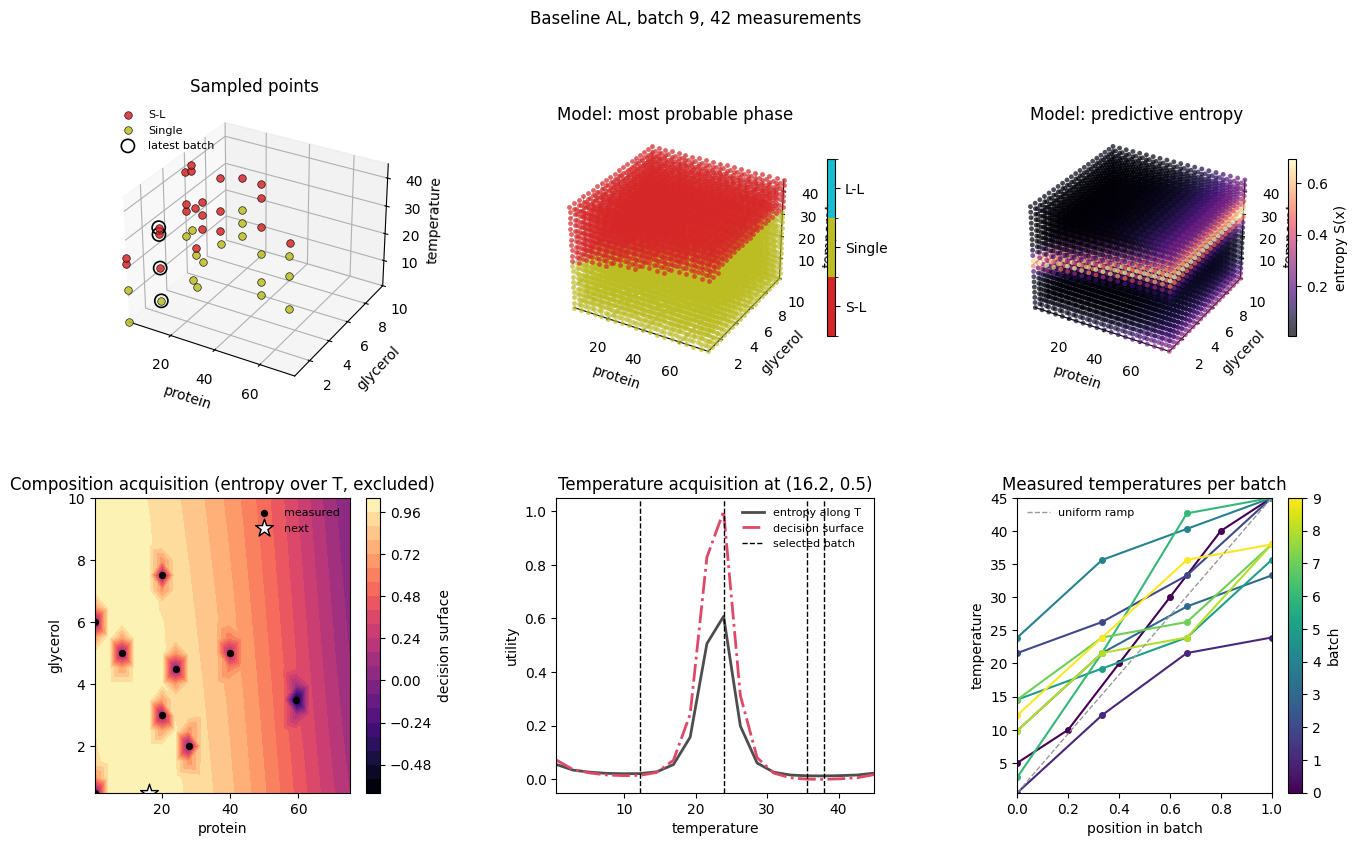

In [9]:
plot_baseline_iteration(ds_result, ds_running, N_SAMPLES - 1, np.sort(ds_result.temperature_next.values),
                        temperature_history, LIMITS, COMPONENTS)
plt.show()